# geopandas II: operaciones espaciales

[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gf0657-programacionsig/2026-ii/blob/main/contenidos/iv-procesamiento-datos-geoespaciales/18-geopandas-operaciones-espaciales.ipynb)

## Trabajo previo

### Lecturas

Antes de la clase, revise las siguientes lecturas, en inglés. La página de la documentación oficial presenta la unión espacial, la operación central de este cuaderno; la lección de Kaggle practica las medidas de distancia y las zonas de influencia con un ejemplo breve.

GeoPandas developers. (s. f.-a). Merging data. En *GeoPandas documentation*. Recuperado el 11 de octubre de 2026, de https://geopandas.org/en/stable/docs/user_guide/mergingdata.html
\
\
Kaggle. (s. f.). Proximity analysis. En *Geospatial analysis*. Kaggle Learn. Recuperado el 11 de octubre de 2026, de https://www.kaggle.com/code/alexisbcook/proximity-analysis

### Otros recursos

En la guía del usuario de geopandas, las páginas sobre [operaciones de conjunto con `overlay()`](https://geopandas.org/en/stable/docs/user_guide/set_operations.html), [agregación con `dissolve()`](https://geopandas.org/en/stable/docs/user_guide/aggregation_with_dissolve.html) y [manipulaciones geométricas](https://geopandas.org/en/stable/docs/user_guide/geometric_manipulations.html) documentan las demás operaciones del cuaderno. El [manual de shapely](https://shapely.readthedocs.io/en/stable/manual.html) describe con detalle los predicados y las operaciones sobre geometrías individuales. El capítulo [Spatial weights](https://geographicdata.science/book/notebooks/04_spatial_weights.html) de Rey et al. (2023) muestra cómo las relaciones de vecindad de este cuaderno sirven de base al análisis espacial.

## Introducción

En la [parte I](https://gf0657-programacionsig.github.io/2026-ii/geopandas-datos-vectoriales/) de la serie *geopandas*, las capas se cargaron, reproyectaron, unieron con tablas por un código y dibujaron en mapas. Las uniones fueron las de pandas: dos tablas que comparten una llave. Pero la mayoría de las preguntas geográficas no tiene llave: ¿cuántos aeropuertos hay en cada país?, ¿qué países atraviesa el Mekong?, ¿cuál es el aeropuerto más cercano a cada capital?, ¿qué capitales están a menos de 50 km de un gran río? Las dos capas de cada pregunta no comparten ninguna columna; lo que comparten es el **espacio**, y la relación entre sus geometrías es la llave.

Este cuaderno presenta las **operaciones espaciales** de geopandas, agrupadas en cinco familias: los **predicados espaciales**, que responden verdadero o falso sobre la relación entre dos geometrías (¿se tocan?, ¿una contiene a la otra?); la **unión espacial**, que combina dos capas por esa relación, como `merge()` lo hace por una llave; las **medidas y geometrías derivadas** (longitud, distancia, centroide, zona de influencia); la **agregación espacial**, que funde polígonos por grupo; y las **operaciones de conjunto** entre capas (intersección, diferencia, recorte). Todas se apoyan en [shapely](https://shapely.readthedocs.io/), que implementa el estándar de geometrías del [Open Geospatial Consortium](https://www.ogc.org/) sobre la biblioteca [GEOS](https://libgeos.org/), la misma que usan PostGIS y QGIS: los resultados son idénticos a los de un SIG de escritorio, pero en código reproducible.

Los datos son los de la parte I: los países, ciudades, aeropuertos, ríos y lagos de [Natural Earth](https://www.naturalearthdata.com/) y los indicadores del [Banco Mundial](https://datos.bancomundial.org/), en los directorios [`datos/natural-earth/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/natural-earth) y [`datos/banco-mundial/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/banco-mundial) del repositorio. Y la regla más importante de la parte I se vuelve aún más importante: toda operación entre dos capas exige que estén en el **mismo SRC**, y toda medida exige un SRC proyectado adecuado a la región.

Como todos los cuadernos del curso, puede ejecutarse en la nube, con la insignia "Abrir en Google Colab", o localmente, en [Visual Studio Code](https://gf0657-programacionsig.github.io/2026-ii/vscode/) con el ambiente `geopython` como kernel. Colab trae geopandas instalado; mapclassify, que se usa en un mapa, se instala allí con `!pip install mapclassify`. El archivo `.ipynb` puede descargarse con el botón de descarga (ícono de flecha hacia abajo) en la parte superior de la página del cuaderno, en el sitio web del curso.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, box

# Direcciones de los directorios de datos en el repositorio del curso
DATOS_NE = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/natural-earth"
DATOS_BM = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/banco-mundial"

# Colores de los cuadernos anteriores
AZUL = "#1F77B4"
NARANJA = "#D97B1B"

print("geopandas", gpd.__version__)

geopandas 1.1.4


## Carga de las capas

Las cinco capas de Natural Earth y los indicadores del Banco Mundial, como en la parte I. Los países se reproyectan a Equal Earth (EPSG:8857), con los tres códigos corregidos para la unión con el Banco Mundial (y los mismos códigos corregidos en las ciudades, que los traen de Natural Earth):

In [2]:
# Países (1:110 M), con los códigos de Kosovo, Palestina y Sudán del Sur corregidos
paises = gpd.read_file(DATOS_NE + "/paises.gpkg")
paises["codigo"] = paises["codigo"].replace({"KOS": "XKX", "PSX": "PSE", "SDS": "SSD"})

# Centroamérica (1:10 M), ríos y lagos (1:110 M) y aeropuertos (1:10 M)
centroamerica = gpd.read_file(DATOS_NE + "/centroamerica.gpkg")
rios = gpd.read_file(DATOS_NE + "/rios.gpkg")
lagos = gpd.read_file(DATOS_NE + "/lagos.gpkg")
aeropuertos = gpd.read_file(DATOS_NE + "/aeropuertos.gpkg")

# Ciudades principales, de tabla con coordenadas a GeoDataFrame
tabla = pd.read_csv(DATOS_NE + "/ciudades.csv")
ciudades = gpd.GeoDataFrame(tabla, geometry=gpd.points_from_xy(tabla["longitud"], tabla["latitud"]), crs=4326)
ciudades["codigo_pais"] = ciudades["codigo_pais"].replace({"KOS": "XKX", "PSX": "PSE", "SDS": "SSD"})

# Indicadores del Banco Mundial de 2024
indicadores = pd.read_csv(DATOS_BM + "/indicadores-2024.csv")

for nombre, capa in [("paises", paises), ("centroamerica", centroamerica), ("rios", rios), ("lagos", lagos), ("aeropuertos", aeropuertos), ("ciudades", ciudades)]:
    print(f"{nombre:14} {len(capa):4} filas  EPSG:{capa.crs.to_epsg()}  {capa.geom_type.unique().tolist()}")

paises          177 filas  EPSG:4326  ['MultiPolygon']
centroamerica     7 filas  EPSG:4326  ['MultiPolygon']
rios             13 filas  EPSG:4326  ['LineString']
lagos            24 filas  EPSG:4326  ['Polygon']
aeropuertos     893 filas  EPSG:4326  ['Point']
ciudades        243 filas  EPSG:4326  ['Point']


Todas las capas están en WGS84. Antes de operar con ellas conviene comprobar algo que en la parte I no hizo falta: que las geometrías sean **válidas**. Un polígono es válido cuando su contorno no se cruza a sí mismo ni sus anillos se tocan de forma indebida; las operaciones de conjunto y la agregación fallan con una geometría inválida, y la reproyección puede producirlas a partir de polígonos válidos, porque desplaza los vértices. `is_valid` lo comprueba y `make_valid()` repara:

In [3]:
# Reproyección a Equal Earth y verificación de validez
paises_ee = paises.to_crs(8857)

print("Inválidas en WGS84:      ", (~paises.is_valid).sum())
print("Inválidas en Equal Earth:", (~paises_ee.is_valid).sum(), paises_ee[~paises_ee.is_valid]["nombre"].tolist())
print(paises_ee[~paises_ee.is_valid].is_valid_reason().tolist())

# Reparación: make_valid() retorna geometrías válidas equivalentes
paises_ee["geometry"] = paises_ee.make_valid()
print("Inválidas tras reparar:  ", (~paises_ee.is_valid).sum())

Inválidas en WGS84:       0
Inválidas en Equal Earth: 2 ['Sudán', 'Mozambique']
['Self-intersection[3232671.01945315 1213275.65655786]', 'Self-intersection[3832714.01890674 -1322027.26845085]']
Inválidas tras reparar:   0


Dos países quedaron con una autointersección al reproyectar. La figura 1 muestra por qué: en ambos, el contorno va y vuelve por casi la misma línea (una púa de 115 km en la frontera de Sudán con Sudán del Sur; un zigzag de medio metro en la desembocadura del río Rovuma, en Mozambique) y en WGS84 los segmentos no llegan a cruzarse por unos pocos metros. La proyección desplaza los vértices lo suficiente para que se crucen. `make_valid()` separa el lazo que se forma como un polígono aparte, de 1 km² en Sudán y de centímetros cuadrados en Mozambique, y el resto del país no cambia. Reparadas, las capas ya no darán problemas.

<figure style="text-align: center;">
  <img
    src="https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/contenidos/iv-procesamiento-datos-geoespaciales/img/validez-geometrias.png"
    alt="Ocho paneles: para Sudán y para Mozambique, una panorámica en Equal Earth y tres acercamientos a la misma escala alrededor de la autointersección, en WGS84 (válida), en Equal Earth (inválida) y tras make_valid() (corregida, con el lazo separado en naranja)"
    width="900"
  >
  <figcaption><strong>Figura 1</strong>. Dos geometrías de la capa de países que dejan de ser válidas al reproyectarlas de WGS84 a Equal Earth, y su reparación con <code>make_valid()</code>. Para cada país: la panorámica en Equal Earth y la misma ventana de metros alrededor de la autointersección en WGS84 (válida), en Equal Earth (inválida) y tras <code>make_valid()</code> (el lazo separado, en naranja). Fuente: elaboración propia con datos de Natural Earth (s. f.).</figcaption>
</figure>

La unión con los indicadores del Banco Mundial, para tener la población de 2024 a mano:

In [4]:
# Unión con los indicadores del Banco Mundial (el GeoDataFrame a la izquierda)
paises_bm = paises_ee.merge(indicadores[["codigo", "poblacion", "pib_per_capita"]], on="codigo", how="left")

print(type(paises_bm), paises_bm.shape)
paises_bm[["codigo", "nombre", "continente", "subregion", "poblacion"]].head()

<class 'geopandas.geodataframe.GeoDataFrame'> (177, 12)


,codigo,nombre,continente,subregion,poblacion
0,FJI,Fiyi,Oceanía,Melanesia,928784.0
1,TZA,Tanzania,África,África oriental,68560157.0
2,SAH,Sahara Occidental,África,África septentrional,NaN
3,CAN,Canadá,América del Norte,América septentrional,41262329.0
4,USA,Estados Unidos,América del Norte,América septentrional,340003797.0


## Predicados espaciales

Un **predicado espacial** es una pregunta sobre la relación entre dos geometrías cuya respuesta es verdadero o falso: ¿se intersecan?, ¿una contiene a la otra?, ¿se tocan solo en el borde? Las relaciones posibles están definidas con precisión en el estándar del OGC (el modelo [DE-9IM](https://es.wikipedia.org/wiki/DE-9IM)), y shapely las implementa como métodos (figura 2).

<figure style="text-align: center;">
  <img
    src="https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/contenidos/iv-procesamiento-datos-geoespaciales/img/relaciones-espaciales.png"
    alt="Seis relaciones espaciales entre dos geometrías"
    width="760"
  >
  <figcaption><strong>Figura 2</strong>. Seis relaciones espaciales entre dos geometrías, A y B, y el predicado que las comprueba. Fuente: elaboración propia con base en Shapely contributors (s. f.).</figcaption>
</figure>

Con dos geometrías individuales (objetos de shapely, extraídos de la columna de geometría con `iloc`), el predicado retorna un booleano. Costa Rica y sus vecinos:

In [5]:
# Geometrías individuales de tres países (objetos de shapely)
costa_rica = paises[paises["nombre"] == "Costa Rica"].geometry.iloc[0]
nicaragua = paises[paises["nombre"] == "Nicaragua"].geometry.iloc[0]
honduras = paises[paises["nombre"] == "Honduras"].geometry.iloc[0]

print("Costa Rica toca a Nicaragua:   ", costa_rica.touches(nicaragua))
print("Costa Rica interseca Nicaragua:", costa_rica.intersects(nicaragua))
print("Costa Rica toca a Honduras:    ", costa_rica.touches(honduras))
print("Costa Rica es disjunta de Honduras:", costa_rica.disjoint(honduras))

Costa Rica toca a Nicaragua:    True
Costa Rica interseca Nicaragua: True
Costa Rica toca a Honduras:     False
Costa Rica es disjunta de Honduras: True


Dos países vecinos se tocan (comparten la frontera, pero no el interior) y por tanto también se intersecan: `intersects` es el predicado más general, verdadero siempre que las geometrías compartan al menos un punto. Lo útil es la forma **vectorizada**: aplicado a una GeoSeries, el predicado se evalúa para cada fila contra una geometría dada y retorna una Series booleana, que sirve de filtro exactamente como en pandas. Los vecinos de Costa Rica y los países que atraviesa el Mekong:

In [6]:
# Predicados vectorizados: cada fila de la capa contra una geometría
vecinos = paises[paises.touches(costa_rica)]
print("Vecinos de Costa Rica:", vecinos["nombre"].tolist())

mekong = rios[rios["nombre"] == "Mekong"].geometry.iloc[0]
atravesados = paises[paises.intersects(mekong)]
print("Países que atraviesa el Mekong:", atravesados["nombre"].tolist())

Vecinos de Costa Rica: ['Panamá', 'Nicaragua']
Países que atraviesa el Mekong: ['Camboya', 'Tailandia', 'Laos', 'Birmania', 'Vietnam', 'China']


La pregunta inversa, ¿en qué país está un punto?, se responde con `contains` y un objeto `Point` construido a mano (con **longitud, latitud**, como siempre) en el SRC de la capa:

In [7]:
# ¿En qué país está la Escuela de Geografía? (punto en WGS84, como la capa)
escuela = Point(-84.0512, 9.9377)

paises[paises.contains(escuela)][["codigo", "nombre", "continente"]]

,codigo,nombre,continente
34,CRI,Costa Rica,América del Norte


La tabla 1 resume los predicados más usados. Dos de ellos son simétricos en sentido inverso: `A.within(B)` equivale a `B.contains(A)`; con ese par se eligen las preguntas "¿qué puntos están dentro de este polígono?" y "¿qué polígono contiene este punto?".

<figure style="text-align: center; margin: 20px 0;">
    <figcaption><strong>Tabla 1</strong>. Predicados espaciales más usados. Fuente: elaboración propia con base en Shapely contributors (s. f.).</figcaption>
    <table class="table table-bordered table-striped" style="margin: 0 auto;">
    <thead>
      <tr><th>Predicado</th><th>Verdadero cuando…</th><th>Uso típico</th></tr>
    </thead>
    <tbody>
      <tr><td><code>intersects</code></td><td>comparten al menos un punto</td><td>el más general: cualquier contacto</td></tr>
      <tr><td><code>disjoint</code></td><td>no comparten ningún punto (lo contrario de <code>intersects</code>)</td><td>excluir lo que toca una zona</td></tr>
      <tr><td><code>touches</code></td><td>comparten puntos del borde, pero no del interior</td><td>vecinos, países fronterizos</td></tr>
      <tr><td><code>within</code></td><td>la primera está completamente dentro de la segunda</td><td>puntos dentro de un polígono</td></tr>
      <tr><td><code>contains</code></td><td>la primera contiene completamente a la segunda</td><td>el polígono que contiene un punto</td></tr>
      <tr><td><code>crosses</code></td><td>una línea atraviesa un polígono u otra línea (comparten parte del interior, pero no toda)</td><td>ríos y carreteras que cruzan regiones</td></tr>
      <tr><td><code>overlaps</code></td><td>dos geometrías de la misma dimensión se superponen parcialmente</td><td>polígonos que se traslapan</td></tr>
      <tr><td><code>covers</code> / <code>covered_by</code></td><td>como <code>contains</code> / <code>within</code>, pero admiten puntos en el borde</td><td>polígonos adyacentes a una frontera</td></tr>
    </tbody>
    </table>
</figure>

*Ejercicios de esta sección: 1 y 2, en la sección de ejercicios al final del cuaderno.*

## Unión espacial

Filtrar con un predicado responde una pregunta sobre **una** geometría. Para responderla sobre todas a la vez (¿en qué país está cada uno de los 893 aeropuertos?) está la **unión espacial**: `gpd.sjoin()` combina dos GeoDataFrames emparejando las filas cuyas geometrías cumplen un predicado, de modo que cada fila del resultado reúne los atributos de ambas capas. Es el `merge()` de la parte II de la serie *pandas*, con la relación espacial como llave. Sus argumentos: las capas izquierda y derecha, `predicate` (por defecto `"intersects"`) y `how` (`"inner"`, `"left"` o `"right"`, con el mismo significado que en `merge()`). Los aeropuertos con el país que los contiene:

In [8]:
# Unión espacial: cada aeropuerto con el país en que está
aeropuertos_pais = gpd.sjoin(
    aeropuertos,
    paises[["codigo", "nombre", "continente", "geometry"]],
    how="left",
    predicate="within"
)

print(aeropuertos_pais.shape)
aeropuertos_pais.head()

(893, 8)


,nombre_left,tipo,iata,geometry,index_right,codigo,nombre_right,continente
0,Sahnewal,small,LUH,POINT (75.95707 30.85036),98.0,IND,India,Asia
1,Solapur,mid,SSE,POINT (75.93306 17.62542),98.0,IND,India,Asia
2,Birsa Munda,mid,IXR,POINT (85.3236 23.31772),98.0,IND,India,Asia
3,Ahwaz,mid,AWZ,POINT (48.74711 31.34316),107.0,IRN,Irán,Asia
4,Gwalior,mid and military,GWL,POINT (78.21722 26.28549),98.0,IND,India,Asia


Tres detalles del resultado. La geometría es la de la capa **izquierda** (los puntos de los aeropuertos); la de la derecha se descarta. Las columnas repetidas en ambas capas reciben los sufijos `_left` y `_right`, como en `merge()`: `nombre_left` es el del aeropuerto y `nombre_right` el del país. Y `index_right` guarda el índice de la fila de la capa derecha con que se emparejó cada fila, útil para volver a ella.

Como toda unión, se verifica. Con `how="left"` se conservaron los 893 aeropuertos; ¿cuántos quedaron sin país?

In [9]:
# Aeropuertos sin país
sin_pais = aeropuertos_pais[aeropuertos_pais["codigo"].isna()]

print(len(sin_pais), "aeropuertos sin país")
sin_pais[["nombre_left", "iata"]].head(8)

104 aeropuertos sin país


,nombre_left,iata
15,Rota Int'l,ROP
40,Vava'u Int'l,VAV
73,Cocos (Keeling) Islands,CCK
74,Corfu Int'l (Ioannis Kapodistrias),CFU
86,Gerrard Smith,CYB
87,Cozumel Int'l,CZM
96,Terrance B. Lettsome Int'l,EIS
99,Vágar,FAE


Más de cien, y la lista explica por qué: son aeropuertos de islas pequeñas y de costas, que a escala 1:110 M no existen o están simplificadas (la capa de aeropuertos es a 1:10 M, cien veces más detallada que la de países). Las dos capas de una unión espacial deben tener **escalas compatibles**; con la capa de países a 1:10 M, casi todos encontrarían su país. Es la misma lección de la parte I, vista desde otro lado: la escala determina para qué sirve una capa.

Con la unión hecha, contar es un `groupby()`, y el conteo se agrega a la capa de países con `merge()` (por el código, con el GeoDataFrame a la izquierda y `fillna(0)` para los países sin aeropuertos), de donde sale un mapa:

In [10]:
# Aeropuertos por país, de vuelta en la capa de países
conteo = aeropuertos_pais.groupby("codigo").size().rename("aeropuertos")

paises_bm = paises_bm.merge(conteo, left_on="codigo", right_index=True, how="left")
paises_bm["aeropuertos"] = paises_bm["aeropuertos"].fillna(0).astype(int)
paises_bm["aeropuertos_por_millon"] = (paises_bm["aeropuertos"] / (paises_bm["poblacion"] / 1_000_000)).round(2)

print("Países sin aeropuertos en la capa:", (paises_bm["aeropuertos"] == 0).sum())
paises_bm.sort_values("aeropuertos", ascending=False)[["nombre", "aeropuertos", "poblacion", "aeropuertos_por_millon"]].head()

Países sin aeropuertos en la capa: 17


,nombre,aeropuertos,poblacion,aeropuertos_por_millon
4,Estados Unidos,132,3.400038e+08,0.39
98,India,51,1.450936e+09,0.04
3,Canadá,44,4.126233e+07,1.07
139,China,38,1.408975e+09,0.03
27,México,38,1.308610e+08,0.29


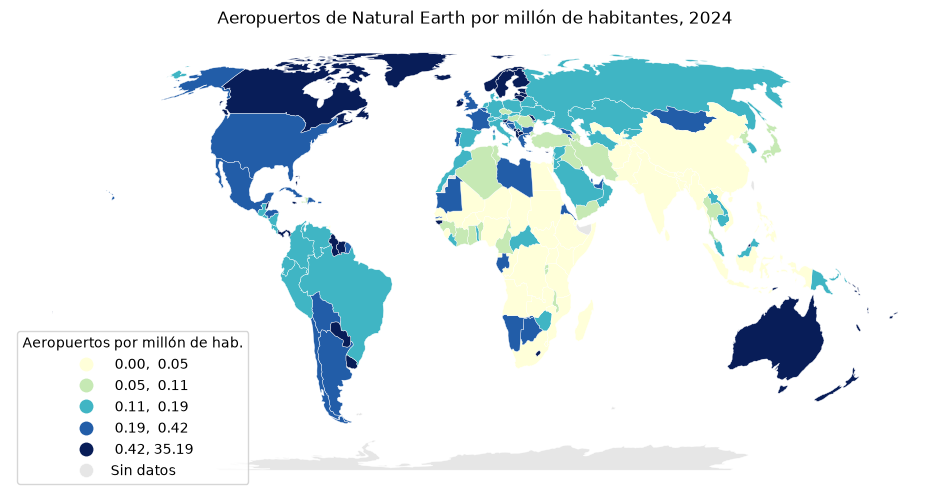

In [11]:
# Mapa de los aeropuertos por millón de habitantes, clasificado en cuantiles (requiere mapclassify)
fig, ax = plt.subplots(figsize=(12, 6))

paises_bm.plot(
    ax=ax, column="aeropuertos_por_millon", cmap="YlGnBu", edgecolor="white", linewidth=0.3,
    scheme="Quantiles", k=5,
    legend=True, legend_kwds={"title": "Aeropuertos por millón de hab.", "loc": "lower left", "fmt": "{:.2f}"},
    missing_kwds={"color": "#E6E6E6", "label": "Sin datos"}
)

ax.set_title("Aeropuertos de Natural Earth por millón de habitantes, 2024")
ax.set_axis_off()

plt.show()

Antes de interpretar el mapa conviene recordar qué mide: los aeropuertos que Natural Earth seleccionó para una capa a 1:10 M, no todos los que existen (Costa Rica aparece con uno solo, y no es el Juan Santamaría). Para un análisis real se usaría una fuente completa, como [OurAirports](https://ourairports.com/data/); para aprender la operación, la capa sirve.

### El orden de las capas

La unión espacial no es simétrica: `sjoin(aeropuertos, paises)` y `sjoin(paises, aeropuertos)` producen los mismos pares, pero con distinta geometría y distinto índice. En la segunda, la geometría es la de los países y cada país aparece **una vez por aeropuerto**, con el índice repetido:

In [12]:
# La misma unión al revés: los países que contienen aeropuertos, una fila por par
paises_aeropuertos = gpd.sjoin(paises[["codigo", "nombre", "geometry"]], aeropuertos, predicate="contains")

print(paises_aeropuertos.shape, "| filas con índice repetido:", paises_aeropuertos.index.duplicated().sum())
paises_aeropuertos[paises_aeropuertos["nombre_left"] == "Panamá"][["nombre_left", "nombre_right", "iata"]]

(789, 7) | filas con índice repetido: 629


,nombre_left,nombre_right,iata
33,Panamá,Enrique Malek Int'l,DAV
33,Panamá,Tocumen Int'l,PTY


El resultado es correcto, pero un índice repetido causa errores más adelante (al asignar columnas o unir por índice). La regla práctica: a la **izquierda** va la capa cuyas filas se quieren conservar en el resultado, con su geometría; si lo que se quiere es un conteo por polígono, se une con los puntos a la izquierda y se agrupa, como arriba.

### Atributo contra posición

Las ciudades traen un código de país como atributo (`codigo_pais`). ¿Coincide con el país que las contiene espacialmente? La unión espacial permite comprobarlo:

In [13]:
# País de cada ciudad por posición, comparado con su atributo
ciudades_pais = gpd.sjoin(ciudades, paises[["codigo", "nombre", "geometry"]], how="left", predicate="within")

sin_pais = ciudades_pais["codigo"].isna()
distinto = ciudades_pais["codigo"].notna() & (ciudades_pais["codigo"] != ciudades_pais["codigo_pais"])

print("Ciudades sin país a 1:110 M:", sin_pais.sum())
print("Ciudades en otro país:      ", distinto.sum())
ciudades_pais[distinto][["nombre_left", "pais", "nombre_right"]]

Ciudades sin país a 1:110 M: 33
Ciudades en otro país:       11


,nombre_left,pais,nombre_right
0,Vatican City,Vatican,Italia
1,San Marino,San Marino,Italia
2,Vaduz,Liechtenstein,Austria
10,Monaco,Monaco,Francia
13,Andorra,Andorra,Francia
108,Brazzaville,Congo (Brazzaville),República Democrática del Congo
139,Jerusalem,Israel,Palestina
142,Nicosia,Cyprus,República Turca del Norte de Chipre
186,Geneva,Switzerland,Francia
241,Singapore,Singapore,Malasia


Una treintena de capitales de islas pequeñas (Tuvalu, Barbados, Comoras) cae fuera de todo polígono, y once ciudades caen en el país **vecino**: la Ciudad del Vaticano y San Marino en Italia, Mónaco y Andorra en Francia, Singapur en Malasia, Hong Kong en China. A 1:110 M los microestados no existen como polígonos, y una ciudad a pocos kilómetros de una frontera simplificada puede quedar del otro lado (Ginebra). Cuando el atributo y la posición discrepan, la escala de la capa de polígonos es la primera sospechosa.

*Ejercicios de esta sección: 3 y 4, en la sección de ejercicios al final del cuaderno.*

## El vecino más cercano

`sjoin()` empareja por una relación topológica; `gpd.sjoin_nearest()` empareja cada geometría de la izquierda con la **más cercana** de la derecha, y con `distance_col` agrega la distancia. Como toda medida, requiere un SRC proyectado: las capas se reproyectan primero. El aeropuerto más cercano a cada ciudad principal:

In [14]:
# Aeropuerto más cercano a cada ciudad principal, con la distancia en metros (Equal Earth)
ciudades_ee = ciudades.to_crs(8857)
aeropuertos_ee = aeropuertos.to_crs(8857)

ciudades_aeropuerto = gpd.sjoin_nearest(
    ciudades_ee,
    aeropuertos_ee[["nombre", "iata", "geometry"]],
    how="left",
    distance_col="distancia_m"
)
ciudades_aeropuerto["distancia_km"] = (ciudades_aeropuerto["distancia_m"] / 1000).round(1)

print(ciudades_aeropuerto.shape)
ciudades_aeropuerto[ciudades_aeropuerto["nombre_left"].isin(["San José", "Managua", "Panama City"])][["nombre_left", "pais", "nombre_right", "iata", "distancia_km"]]

(243, 13)


,nombre_left,pais,nombre_right,iata,distancia_km
63,Managua,Nicaragua,Augusto Cesar Sandino Int'l,MGA,9.3
71,Panama City,Panama,Tocumen Int'l,PTY,19.5
89,San José,Costa Rica,Nacional Tobías Bolaños,SYQ,5.5


In [15]:
# Las capitales más alejadas de un aeropuerto de la capa
ciudades_aeropuerto.sort_values("distancia_km", ascending=False)[["nombre_left", "pais", "nombre_right", "iata", "distancia_km"]].head()

,nombre_left,pais,nombre_right,iata,distancia_km
17,Juba,South Sudan,Entebbe Int'l,EBB,620.7
9,Bir Lehlou,Western Sahara,Gran Canaria,LPA,557.8
25,Dodoma,Tanzania,Zanzibar,ZNZ,331.6
61,Dushanbe,Tajikistan,Tashkent Int'l,TAS,307.0
131,Naypyidaw,Myanmar,Mandalay Int'l,MDL,249.5


Juba, la capital de Sudán del Sur, queda a más de 600 km del aeropuerto más cercano **de la capa**: tiene aeropuerto, pero Natural Earth no lo incluyó. De nuevo, el resultado es correcto para los datos y engañoso para el mundo. Las distancias en Equal Earth son aproximadas (la proyección conserva las áreas, no las distancias); para distancias precisas en una región se usa su proyección local, como se muestra enseguida.

*Ejercicios de esta sección: 5, en la sección de ejercicios al final del cuaderno.*

## Medidas y geometrías derivadas

La parte I midió áreas con `area`. Las demás medidas siguen la misma regla (SRC proyectado, unidades del SRC): `length` da la longitud de las líneas y `distance()` la distancia entre geometrías. Los ríos, en Equal Earth:

In [16]:
# Longitud de los ríos de la capa, en km
rios_ee = rios.to_crs(8857)
rios_ee["longitud_km"] = (rios_ee.length / 1000).round(0)

rios_ee[["nombre", "longitud_km"]].sort_values("longitud_km", ascending=False)

,nombre,longitud_km
9,Nile,4968.0
8,Chang,4437.0
10,Amazonas,4406.0
11,Mississippi,4294.0
2,Ob,4236.0
1,Mekong,4121.0
7,Lena,4017.0
6,Congo,3627.0
3,Peace,3157.0
5,Paraná,2759.0


El Nilo mide 6 650 km y la capa le da 5 000: a 1:110 M las líneas están **generalizadas** (sin meandros), y la longitud medida es siempre menor que la real. También aparece un "Yangtze" de 4 km, un fragmento junto al "Chang" (Chang Jiang es el nombre chino del Yangtsé): los datos traen sorpresas que solo se descubren mirándolos.

Para las distancias en Centroamérica se usa CR-SIRGAS / CRTM05 (EPSG:8908), y se comparan con las de Equal Earth y con la distancia **geodésica**, la calculada sobre el elipsoide, que es la referencia:

In [17]:
# Distancia de San José a las demás capitales de Centroamérica, en tres SRC y sobre el elipsoide
from pyproj import Geod

capitales = ciudades[ciudades["codigo_pais"].isin(centroamerica["codigo"]) & ciudades["capital"]].copy()
san_jose = capitales[capitales["nombre"] == "San José"].geometry.iloc[0]

capitales_crtm05 = capitales.to_crs(8908)
capitales_ee = capitales.to_crs(8857)

capitales["grados_wgs84"] = capitales.distance(san_jose).round(2)
capitales["km_crtm05"] = (capitales_crtm05.distance(capitales_crtm05[capitales_crtm05["nombre"] == "San José"].geometry.iloc[0]) / 1000).round(0)
capitales["km_equal_earth"] = (capitales_ee.distance(capitales_ee[capitales_ee["nombre"] == "San José"].geometry.iloc[0]) / 1000).round(0)
capitales["km_geodesica"] = (Geod(ellps="WGS84").inv(
    [san_jose.x] * len(capitales), [san_jose.y] * len(capitales), capitales.geometry.x, capitales.geometry.y
)[2] / 1000).round(0)

capitales[["nombre", "pais", "grados_wgs84", "km_crtm05", "km_equal_earth", "km_geodesica"]].sort_values("km_geodesica")

/tmp/ipykernel_1376660/3010564433.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  capitales["grados_wgs84"] = capitales.distance(san_jose).round(2)


,nombre,pais,grados_wgs84,km_crtm05,km_equal_earth,km_geodesica
89,San José,Costa Rica,0.00,0.0,0.0,0.0
63,Managua,Nicaragua,3.11,342.0,334.0,342.0
71,Panama City,Panama,4.65,512.0,440.0,511.0
54,Tegucigalpa,Honduras,5.21,574.0,580.0,573.0
90,San Salvador,El Salvador,6.36,698.0,646.0,697.0
98,Guatemala City,Guatemala,7.97,873.0,804.0,872.0
115,Belmopan,Belize,8.68,956.0,981.0,955.0


La distancia en WGS84 sale en grados, que no son una unidad de longitud (geopandas lo advierte). CRTM05 coincide con la distancia geodésica en toda la región, con error menor del 1 %; Equal Earth, diseñada para el mundo entero, se equivoca hasta en un 14 % (Ciudad de Panamá). Para medir en una región, su proyección local.

### Centroides y puntos representativos

`centroid` retorna el centro de masa de cada geometría, útil para colocar etiquetas o para resumir un polígono en un punto. Pero el centroide de un polígono cóncavo o de un multipolígono puede caer **fuera** de él; `representative_point()` garantiza un punto interior:

In [18]:
# Centroides que caen fuera de su propio país
centroides = paises_ee.centroid
fuera = ~paises_ee.contains(centroides)

print(fuera.sum(), "centroides fuera del polígono:", paises_ee[fuera]["nombre"].tolist())
print("Puntos representativos fuera:", (~paises_ee.contains(paises_ee.representative_point())).sum())

13 centroides fuera del polígono: ['Fiyi', 'Indonesia', 'Chile', 'Haití', 'Bahamas', 'Francia', 'Israel', 'Vietnam', 'Croacia', 'Islas Salomón', 'Filipinas', 'Malasia', 'Japón']
Puntos representativos fuera: 0


Chile, Japón, Indonesia o Filipinas: países alargados o archipiélagos, cuyo centro de masa queda en el mar. Para etiquetar un mapa, `representative_point()`; para análisis que requieran el centro geométrico, `centroid`, sabiendo dónde cae.

### Zonas de influencia

`buffer(distancia)` construye el polígono de todos los puntos a menos de esa distancia de la geometría: una **zona de influencia**, en las unidades del SRC. Combinada con una unión espacial, responde preguntas de proximidad: ¿qué ciudades principales están a menos de 50 km de uno de los grandes ríos?

In [19]:
# Zona de 50 km alrededor de cada río, y las ciudades dentro de ella
zonas_rios = rios_ee[["nombre", "geometry"]].copy()
zonas_rios["geometry"] = zonas_rios.buffer(50_000)

print(zonas_rios.geom_type.unique().tolist())

ciudades_rio = gpd.sjoin(ciudades_ee, zonas_rios, predicate="within")
ciudades_rio[["nombre_left", "pais", "nombre_right"]].sort_values("nombre_right")

['Polygon']


,nombre_left,pais,nombre_right
171,Dhaka,Bangladesh,Brahmaputra
232,Shanghai,China,Chang
108,Brazzaville,Congo (Brazzaville),Congo
201,Kinshasa,Congo (Kinshasa),Congo
20,Bratislava,Slovakia,Donau
112,Belgrade,Serbia,Donau
146,Budapest,Hungary,Donau
212,Vienna,Austria,Donau
107,Vientiane,Laos,Mekong
121,Phnom Penh,Cambodia,Mekong


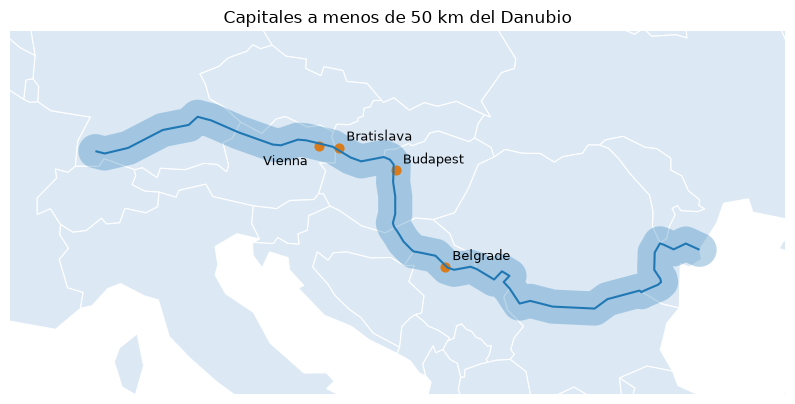

In [20]:
# Mapa: el Danubio, su zona de 50 km y las capitales dentro de ella
danubio = zonas_rios[zonas_rios["nombre"] == "Donau"]
capitales_danubio = ciudades_rio[ciudades_rio["nombre_right"] == "Donau"]

fig, ax = plt.subplots(figsize=(10, 6))

paises_ee.plot(ax=ax, color="#DCE9F5", edgecolor="white", linewidth=0.8)
danubio.plot(ax=ax, color=AZUL, alpha=0.3)
rios_ee[rios_ee["nombre"] == "Donau"].plot(ax=ax, color=AZUL, linewidth=1.5)
capitales_danubio.plot(ax=ax, color=NARANJA, markersize=40)

for punto, nombre in zip(capitales_danubio.geometry, capitales_danubio["nombre_left"]):
    desplazamiento = (-40, -14) if nombre == "Vienna" else (5, 5)  # Viena y Bratislava están muy cerca
    ax.annotate(nombre, (punto.x, punto.y), xytext=desplazamiento, textcoords="offset points", fontsize=9)

xmin, ymin, xmax, ymax = danubio.total_bounds
ax.set_xlim(xmin - 200_000, xmax + 200_000)
ax.set_ylim(ymin - 200_000, ymax + 200_000)
ax.set_title("Capitales a menos de 50 km del Danubio")
ax.set_axis_off()

plt.show()

El buffer de una línea es un polígono; el de un punto, un círculo; el de un polígono, el polígono agrandado (y con distancia negativa, encogido). Como la zona se construye en metros, el SRC debe ser proyectado: en WGS84, `buffer(1)` dibuja un "círculo" de un grado, que no es un círculo ni mide lo mismo en todas partes (ver la clínica de errores). Otras geometrías derivadas, con el mismo patrón: `convex_hull` (la envolvente convexa), `envelope` (el rectángulo que encierra la geometría), `boundary` (el contorno) y `simplify(tolerancia)` (menos vértices).

*Ejercicios de esta sección: 6 y 7, en la sección de ejercicios al final del cuaderno.*

## Agregación espacial

`groupby()` agrega las columnas de atributos; `dissolve()` hace lo mismo y además **funde las geometrías** de cada grupo en una sola, con `by` para la columna de agrupación y `aggfunc` para las demás columnas (como en `agg()`). Los continentes a partir de los países, con su población:

In [21]:
# Países fundidos por continente, con la población sumada y los países contados
continentes = paises_bm.dissolve(by="continente", aggfunc={"poblacion": "sum", "nombre": "count"}).rename(columns={"nombre": "paises"})

print(continentes.shape, continentes.geom_type.unique().tolist())
continentes[["paises", "poblacion"]].sort_values("poblacion", ascending=False)

(8, 3) ['MultiPolygon', 'Polygon']


,paises,poblacion
continente,,
Asia,47,4.755842e+09
África,51,1.509203e+09
Europa,39,7.417813e+08
América del Norte,18,6.067241e+08
América del Sur,13,4.352993e+08
Oceanía,7,4.542919e+07
Antártida,1,0.000000e+00
Siete mares (océano abierto),1,0.000000e+00


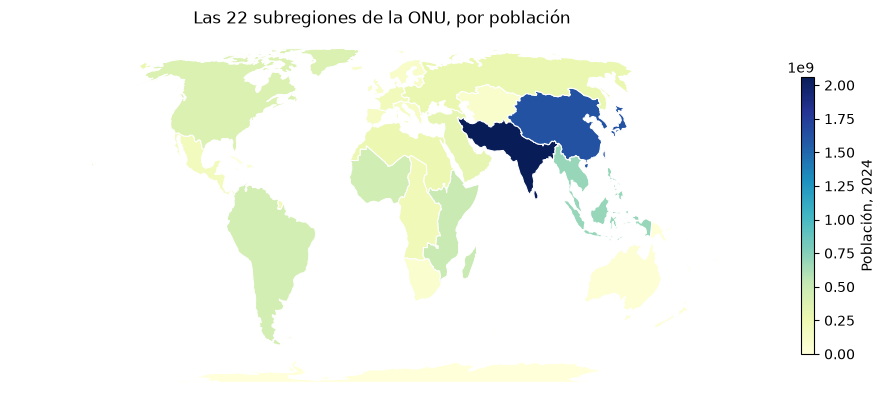

In [22]:
# Mapa de las subregiones de la ONU
subregiones = paises_bm.dissolve(by="subregion", aggfunc={"poblacion": "sum"})

fig, ax = plt.subplots(figsize=(12, 6))

subregiones.plot(ax=ax, column="poblacion", cmap="YlGnBu", edgecolor="white", linewidth=0.8, legend=True,
                 legend_kwds={"label": "Población, 2024", "shrink": 0.6})

ax.set_title(f"Las {len(subregiones)} subregiones de la ONU, por población")
ax.set_axis_off()

plt.show()

La columna de agrupación queda como índice (como en `groupby()`), y las fronteras interiores desaparecen: cada subregión es un polígono o multipolígono. Las geometrías inválidas que se repararon al inicio habrían hecho fallar esta operación (ver la clínica). Para capas grandes de polígonos que no se traslapan, `dissolve(..., method="coverage")` es mucho más rápido.

*Ejercicios de esta sección: 8, en la sección de ejercicios al final del cuaderno.*

## Operaciones de conjunto entre capas

`gpd.overlay()` combina **dos capas de polígonos** en una nueva, cuyas geometrías son las intersecciones, uniones o diferencias de las originales y cuyos atributos vienen de ambas (tabla 2). ¿Cuánto de cada lago le corresponde a cada país?

In [23]:
# Intersección de lagos y países: un polígono por cada parte de un lago en un país
lagos_ee = lagos.to_crs(8857)

lagos_pais = gpd.overlay(lagos_ee, paises_ee[["codigo", "nombre", "geometry"]], how="intersection")
lagos_pais["area_km2"] = (lagos_pais.area / 1_000_000).round(0)

print(lagos.shape, "->", lagos_pais.shape)
lagos_pais[lagos_pais["nombre_1"].isin(["Lake Victoria", "Lago Titicaca"])][["nombre_1", "nombre_2", "area_km2"]]

(24, 2) -> (36, 5)


,nombre_1,nombre_2,area_km2
9,Lake Victoria,Tanzania,33758.0
10,Lake Victoria,Kenia,2299.0
11,Lake Victoria,Uganda,25994.0
25,Lago Titicaca,Bolivia,2516.0
26,Lago Titicaca,Perú,4722.0


Los 24 lagos se convirtieron en 36 partes, porque varios son compartidos: el Victoria se reparte entre Tanzania, Uganda y Kenia, y el Titicaca entre Perú y Bolivia (las columnas repetidas reciben los sufijos `_1` y `_2`). Con `how="difference"` se obtiene lo que queda de la primera capa al quitar la segunda; sirve para cerrar una cuenta pendiente de la parte I, donde el área de Nicaragua superaba en un 7 % la superficie terrestre del Banco Mundial por los lagos:

In [24]:
# Nicaragua sin sus lagos, comparada con la superficie terrestre del Banco Mundial
nicaragua_ee = paises_ee[paises_ee["nombre"] == "Nicaragua"]
nicaragua_sin_lagos = gpd.overlay(nicaragua_ee, lagos_ee, how="difference")

print("Área con lagos:   ", round(nicaragua_ee.area.iloc[0] / 1_000_000), "km²")
print("Área sin lagos:   ", round(nicaragua_sin_lagos.area.iloc[0] / 1_000_000), "km²")
print("Banco Mundial:    ", indicadores.loc[indicadores["codigo"] == "NIC", "area_km2"].iloc[0], "km²")

Área con lagos:    129544 km²
Área sin lagos:    124320 km²
Banco Mundial:     120340.0 km²


La diferencia se reduce de 9 000 a 4 000 km²: la capa de lagos a 1:110 M solo tiene el Cocibolca, y simplificado; el resto es el Xolotlán y la generalización de la costa.

<figure style="text-align: center; margin: 20px 0;">
    <figcaption><strong>Tabla 2</strong>. Operaciones de conjunto de <code>overlay()</code> entre dos capas de polígonos, A y B. Fuente: elaboración propia con base en GeoPandas developers (s. f.-b).</figcaption>
    <table class="table table-bordered table-striped" style="margin: 0 auto;">
    <thead>
      <tr><th><code>how</code></th><th>Geometrías del resultado</th><th>Ejemplo</th></tr>
    </thead>
    <tbody>
      <tr><td><code>"intersection"</code></td><td>las partes de A que están en B (atributos de ambas)</td><td>parte de cada lago en cada país</td></tr>
      <tr><td><code>"union"</code></td><td>todas las partes de A y de B, divididas donde se cruzan</td><td>cuadrícula de dos zonificaciones</td></tr>
      <tr><td><code>"difference"</code></td><td>las partes de A que no están en B</td><td>un país sin sus lagos</td></tr>
      <tr><td><code>"symmetric_difference"</code></td><td>las partes de A o de B que no están en ambas</td><td>cambios entre dos versiones de una capa</td></tr>
      <tr><td><code>"identity"</code></td><td>A completa, dividida donde la cruza B</td><td>parcelas divididas por una zona de riesgo</td></tr>
    </tbody>
    </table>
</figure>

### Recorte

Cuando solo interesa limitar una capa a un área (sin combinar atributos), `gpd.clip()` **recorta** cualquier capa (puntos, líneas o polígonos) con la extensión de otra o con una geometría; el recorte de líneas y polígonos corta las geometrías en el borde. Los ríos de América del Sur, y los países de la región de Centroamérica recortados con un rectángulo construido con `box()`:

In [25]:
# Recorte de los ríos con el continente, y de los países con un rectángulo (xmin, ymin, xmax, ymax)
america_sur = paises[paises["continente"] == "América del Sur"]
rios_america_sur = gpd.clip(rios, america_sur)

region = box(-92.5, 5.5, -77, 18.5)
paises_region = gpd.clip(paises, region)

print("Ríos de América del Sur:", rios_america_sur["nombre"].tolist())
print("Países en el rectángulo: ", paises_region["nombre"].tolist())

Ríos de América del Sur: ['Paraná', 'Amazonas']
Países en el rectángulo:  ['Colombia', 'Panamá', 'Costa Rica', 'Nicaragua', 'El Salvador', 'Honduras', 'Guatemala', 'Belice', 'Jamaica', 'México']


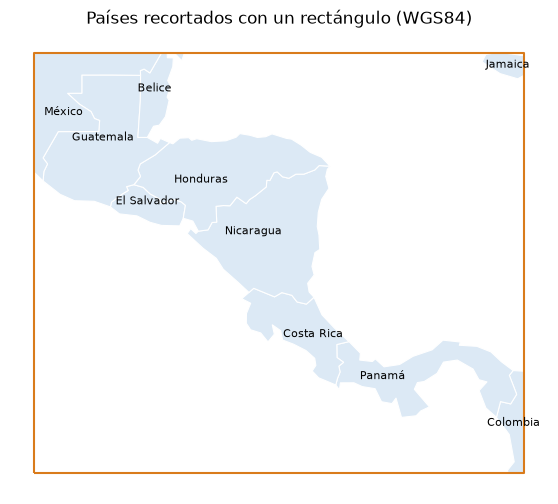

In [26]:
# Mapa de la región, con los países recortados y el rectángulo
fig, ax = plt.subplots(figsize=(9, 6))

paises_region.plot(ax=ax, color="#DCE9F5", edgecolor="white", linewidth=0.8)
gpd.GeoSeries([region], crs=4326).boundary.plot(ax=ax, color=NARANJA, linewidth=1.5)

for punto, nombre in zip(paises_region.representative_point(), paises_region["nombre"]):
    ax.annotate(nombre, (punto.x, punto.y), ha="center", fontsize=8)

ax.set_title("Países recortados con un rectángulo (WGS84)")
ax.set_axis_off()

plt.show()

Colombia, México y Jamaica entran recortados por el borde del rectángulo, lo que un filtro por atributo (`continente == ...`) no haría. Recortar es la forma usual de preparar un mapa regional a partir de capas mundiales. Para análisis que no se agoten en un mapa conviene mantener la capa completa y filtrar al final.

*Ejercicios de esta sección: 9 y 10, en la sección de ejercicios al final del cuaderno.*

## Clínica de errores

Los errores propios de las operaciones espaciales, provocados a propósito. El primero no detiene el programa: solo avisa y retorna una unión **vacía**, que el código siguiente tomaría por buena.

In [27]:
# UserWarning: "CRS mismatch between the CRS of left geometries and the CRS of right geometries."
# Las capas de una unión espacial deben estar en el mismo SRC: aquí los aeropuertos en WGS84 y
# los países en Equal Earth no comparten ningún punto, y el resultado tiene cero filas.
union = gpd.sjoin(aeropuertos, paises_ee, predicate="within")
print(union.shape)

(0, 14)


/tmp/ipykernel_1376660/2330537591.py:4: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4326
Right CRS: EPSG:8857

  union = gpd.sjoin(aeropuertos, paises_ee, predicate="within")


In [28]:
# UserWarning: "Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect."
# Un buffer de 1 "unidad" en WGS84 es de 1 grado: en el ecuador (Quito) la zona mide unos 222 km de
# ancho, pero en Islandia (Reykjavík) menos de 100, porque un grado de longitud se estrecha hacia los
# polos: no es un círculo. Lo mismo ocurre con distance(), length y sjoin_nearest() en WGS84.
zona_grados = ciudades[ciudades["nombre"].isin(["Quito", "Reykjavík"])].set_index("nombre").buffer(1)

# Dimensiones reales de cada zona, medidas sobre el elipsoide
geod = Geod(ellps="WGS84")
dimensiones = zona_grados.bounds
dimensiones["ancho_km"] = [round(geod.inv(f.minx, (f.miny + f.maxy) / 2, f.maxx, (f.miny + f.maxy) / 2)[2] / 1000) for f in dimensiones.itertuples()]
dimensiones["alto_km"] = [round(geod.inv((f.minx + f.maxx) / 2, f.miny, (f.minx + f.maxx) / 2, f.maxy)[2] / 1000) for f in dimensiones.itertuples()]
dimensiones[["ancho_km", "alto_km"]]

/tmp/ipykernel_1376660/991332356.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  zona_grados = ciudades[ciudades["nombre"].isin(["Quito", "Reykjavík"])].set_index("nombre").buffer(1)


,ancho_km,alto_km
nombre,,
Reykjavík,97,223
Quito,223,221


In [29]:
# GEOSException: "TopologyException: side location conflict ..."
# dissolve() y overlay() fallan con una geometría inválida. Aquí se usa la capa reproyectada
# sin reparar (la autointersección de Sudán y Mozambique). Solución: make_valid() antes de operar.
paises.to_crs(8857).dissolve(by="continente")

GEOSException: TopologyException: side location conflict at 3232671.0194531484 1213275.6565578561. This can occur if the input geometry is invalid.

In [30]:
# ValueError: "'left_df' should be GeoDataFrame, got <class 'pandas.DataFrame'>"
# La tabla de ciudades leída con pandas no tiene geometría: hay que convertirla con points_from_xy().
gpd.sjoin(tabla, paises, predicate="within")

ValueError: 'left_df' should be GeoDataFrame, got <class 'pandas.DataFrame'>

## Asistentes de IA para generar operaciones espaciales

Las pautas de los cuadernos anteriores aplican: describir las capas en el contexto (columnas, tipo de geometría y, sobre todo, el SRC de cada una), pedir el patrón del curso y verificar el resultado. Para las operaciones espaciales, las comprobaciones son cuatro: que las dos capas estén en el **mismo SRC** y que ese SRC sea proyectado si se mide; que el **predicado** y el **orden de las capas** correspondan a la pregunta (`within` con los puntos a la izquierda para contarlos por polígono); que el número de filas del resultado sea el esperado (con `how="left"`, el de la capa izquierda) y que los no emparejados se expliquen; y que un par de resultados conocidos sean correctos (Costa Rica tiene dos vecinos). Un prompt de ejemplo:

> Actúe como asistente de análisis de datos geoespaciales con geopandas **(rol)**. Tengo dos GeoDataFrames en EPSG:8857: `ciudades_ee`, con 243 puntos de ciudades principales y las columnas `nombre`, `pais` y `poblacion`, y `paises_ee`, con 177 polígonos de países y las columnas `codigo`, `nombre` y `continente` **(contexto)**. Escriba el código que calcule, para cada país, cuántas ciudades principales contiene y la población total de esas ciudades, agregue las dos columnas a `paises_ee` (con cero para los países sin ciudades) y muestre los diez países con más ciudades **(tarea)**. Use `gpd.sjoin()` con los puntos a la izquierda, `groupby()` y `merge()` con el GeoDataFrame a la izquierda, y agregue un comentario por paso **(formato)**.

## Resumen

- Los **predicados espaciales** (`intersects`, `touches`, `within`, `contains`, `crosses`, `disjoint`…) responden verdadero o falso sobre la relación entre dos geometrías; vectorizados sobre una GeoSeries, filtran una capa como el filtrado booleano de pandas.
- La **unión espacial** `gpd.sjoin()` combina dos capas por un predicado, como `merge()` lo hace por una llave: conserva la geometría de la capa **izquierda**, agrega sufijos `_left` y `_right` y la columna `index_right`, y se verifica (filas sin pareja, índices repetidos). Las escalas de las dos capas deben ser compatibles. `gpd.sjoin_nearest()` empareja con la geometría más cercana y mide la distancia.
- Las **medidas** (`area`, `length`, `distance()`) y las **geometrías derivadas** (`buffer()`, `centroid`, `representative_point()`, `convex_hull`, `envelope`, `simplify()`) requieren un SRC proyectado adecuado a la región: Equal Earth para el mundo, CRTM05 para Costa Rica. Las líneas generalizadas miden menos que las reales.
- `dissolve()` **agrega** por grupo las geometrías y los atributos; `gpd.overlay()` produce la intersección, unión o diferencia de dos capas de polígonos, con los atributos de ambas; `gpd.clip()` **recorta** cualquier capa con un área.
- Las geometrías deben ser **válidas** (`is_valid`, `make_valid()`), en especial tras reproyectar, o las operaciones de conjunto fallan.
- Toda operación entre dos capas exige el **mismo SRC**: la unión espacial con SRC distintos no falla, solo avisa y retorna cero filas.

## Ejercicios

Los ejercicios se agrupan según la sección del cuaderno a la que corresponden; se recomienda realizarlos al concluir la sección respectiva. Resuélvalos en este mismo cuaderno (en su copia de Colab o local), después de ejecutar las celdas de las secciones anteriores. Varios incluyen una **celda de verificación** que examina el objeto creado: para que funcione, nombre los objetos como se indica en el enunciado y ejecute la celda tal cual después de resolver el ejercicio (en la versión publicada muestra un recordatorio, porque los ejercicios no están resueltos). Las [soluciones de estos ejercicios](https://gf0657-programacionsig.github.io/2026-ii/soluciones-geopandas-operaciones-espaciales) se publican después de la clase correspondiente.

### Predicados espaciales

1. Guarde en `vecinos_brasil` los países que tocan a Brasil (con `touches` y la geometría de Brasil extraída de `paises`). ¿Cuántos son y cuál de ellos sorprende? Pista: revise de qué continente es cada uno.

In [31]:
# Celda de verificación del ejercicio 1: ejecútela tal cual
try:
    assert isinstance(vecinos_brasil, gpd.GeoDataFrame) and len(vecinos_brasil) == 10, "Brasil tiene 10 vecinos en la capa"
    assert "Francia" in vecinos_brasil["nombre"].tolist(), "Uno de los vecinos es Francia (por la Guayana Francesa)"
    print("Ejercicio 1: ¡correcto!")
except NameError:
    print("Aún no se ha definido vecinos_brasil (ejercicio 1).")

Aún no se ha definido vecinos_brasil (ejercicio 1).


2. Guarde en `paises_danubio` los países que atraviesa el Danubio (`"Donau"` en la capa de ríos) y dibújelos en `ax_2` con el río encima, con título y sin ejes. ¿Cuántos países son? Compare `intersects` con `crosses`: ¿dan lo mismo aquí? ¿Cuándo darían resultados distintos?

In [32]:
# Celda de verificación del ejercicio 2: ejecútela tal cual
try:
    assert isinstance(paises_danubio, gpd.GeoDataFrame) and len(paises_danubio) == 9, "El Danubio atraviesa 9 países de la capa"
    assert ax_2.get_title() and not ax_2.axison, "Falta el título o los ejes siguen visibles"
    assert len(ax_2.collections) >= 2, "Faltan los países o el río en el mapa"
    print("Ejercicio 2: ¡correcto!")
except NameError:
    print("Aún no se han definido paises_danubio y ax_2 (ejercicio 2).")

Aún no se han definido paises_danubio y ax_2 (ejercicio 2).


### Unión espacial

3. Con una unión espacial, cuente los aeropuertos de cada **continente** y guarde el resultado en `aeropuertos_continente` (una Series con el continente como índice, ordenada de mayor a menor). ¿Cuál continente tiene más aeropuertos en la capa? ¿Cuántos aeropuertos no tienen continente y por qué?

In [33]:
# Celda de verificación del ejercicio 3: ejecútela tal cual
try:
    assert isinstance(aeropuertos_continente, pd.Series) and aeropuertos_continente.index[0] == "América del Norte", "América del Norte debería tener más aeropuertos"
    assert aeropuertos_continente.sum() == 789, "Los aeropuertos con continente deben sumar 789"
    print("Ejercicio 3: ¡correcto!")
except NameError:
    print("Aún no se ha definido aeropuertos_continente (ejercicio 3).")

Aún no se ha definido aeropuertos_continente (ejercicio 3).


4. Una `ciudades_ee` con `paises_ee` para calcular, por país, cuántas ciudades principales contiene y la población total de esas ciudades. Agregue las dos columnas a una copia de `paises_ee` llamada `paises_ciudades` (con cero para los países sin ciudades) y muestre los diez países con más ciudades. ¿Cuántos países no tienen ninguna ciudad principal en la capa? Es el ejercicio del prompt de la sección de asistentes: resuélvalo primero a mano.

In [34]:
# Celda de verificación del ejercicio 4: ejecútela tal cual
try:
    assert isinstance(paises_ciudades, gpd.GeoDataFrame) and len(paises_ciudades) == 177, "paises_ciudades debe ser un GeoDataFrame con los 177 países"
    assert "ciudades" in paises_ciudades.columns and paises_ciudades["ciudades"].sum() == 210, "Las ciudades con país deben sumar 210"
    assert (paises_ciudades["ciudades"] == 0).sum() == 16, "16 países no tienen ciudades principales en la capa"
    print("Ejercicio 4: ¡correcto!")
except NameError:
    print("Aún no se ha definido paises_ciudades (ejercicio 4).")

Aún no se ha definido paises_ciudades (ejercicio 4).


### El vecino más cercano

5. Para cada aeropuerto de África (filtre `aeropuertos_pais` por continente, elimine la columna `index_right` que dejó la unión anterior y reproyecte a Equal Earth), encuentre la ciudad principal más cercana y la distancia en km, en `aeropuertos_ciudad`. ¿Cuál aeropuerto está más lejos de una ciudad principal? Muestre los cinco más alejados.

In [35]:
# Celda de verificación del ejercicio 5: ejecútela tal cual
try:
    assert isinstance(aeropuertos_ciudad, gpd.GeoDataFrame) and len(aeropuertos_ciudad) == 85, "África tiene 85 aeropuertos en la capa"
    assert aeropuertos_ciudad.crs.to_epsg() == 8857, "La distancia se mide en Equal Earth (EPSG:8857)"
    assert "distancia_km" in aeropuertos_ciudad.columns and aeropuertos_ciudad["distancia_km"].max() > 500, "Falta distancia_km o las unidades no son km"
    print("Ejercicio 5: ¡correcto!")
except NameError:
    print("Aún no se ha definido aeropuertos_ciudad (ejercicio 5).")

Aún no se ha definido aeropuertos_ciudad (ejercicio 5).


### Medidas y geometrías derivadas

6. Reproyecte `centroamerica` y las capitales de Centroamérica a CRTM05 y calcule, para cada país, la distancia en km de su capital al **centroide** del país, en `capitales_centroide` (un GeoDataFrame con las columnas `pais` y `distancia_km`). ¿En cuál país la capital está más lejos de su centro geométrico? Pista: una `capitales_crtm05` con `centroamerica_crtm05` por el código de país, y `distance()` acepta una GeoSeries alineada por índice, o use `align=False`.

In [36]:
# Celda de verificación del ejercicio 6: ejecútela tal cual
try:
    assert len(capitales_centroide) == 7 and capitales_centroide.crs.to_epsg() == 8908, "Deben ser las 7 capitales en CRTM05"
    assert capitales_centroide["distancia_km"].between(5, 300).all(), "Las distancias deberían estar entre 5 y 300 km (¿unidades?)"
    print("Ejercicio 6: ¡correcto!")
except NameError:
    print("Aún no se ha definido capitales_centroide (ejercicio 6).")

Aún no se ha definido capitales_centroide (ejercicio 6).


7. Construya en CRTM05 una zona de influencia de 300 km alrededor de San José y guarde en `aeropuertos_cerca` los aeropuertos de la capa que están dentro (con `within` o con una unión espacial). Dibújelos en `ax_7` sobre `centroamerica`, con la zona en color claro, título y sin ejes. ¿Cuántos son y de qué países?

In [37]:
# Celda de verificación del ejercicio 7: ejecútela tal cual
try:
    assert isinstance(aeropuertos_cerca, gpd.GeoDataFrame) and len(aeropuertos_cerca) == 2, "Hay 2 aeropuertos de la capa a menos de 300 km de San José"
    assert aeropuertos_cerca.crs.to_epsg() == 8908, "aeropuertos_cerca debe estar en CRTM05 (EPSG:8908)"
    assert ax_7.get_title() and not ax_7.axison, "Falta el título o los ejes siguen visibles"
    print("Ejercicio 7: ¡correcto!")
except NameError:
    print("Aún no se han definido aeropuertos_cerca y ax_7 (ejercicio 7).")

Aún no se han definido aeropuertos_cerca y ax_7 (ejercicio 7).


### Agregación espacial

8. Funda los países por **grupo de ingreso** (`grupo_ingreso` de `paises_bm`) en `grupos_ingreso`, con la población de 2024 sumada y los países contados, y dibuje en `ax_8` un mapa con un color por grupo y leyenda. ¿Qué grupo tiene más población? ¿Y más países?

In [38]:
# Celda de verificación del ejercicio 8: ejecútela tal cual
try:
    assert isinstance(grupos_ingreso, gpd.GeoDataFrame) and len(grupos_ingreso) == 5, "Hay 5 grupos de ingreso"
    assert "poblacion" in grupos_ingreso.columns and grupos_ingreso["poblacion"].idxmax() == "4. Ingreso mediano bajo", "El grupo más poblado es el de ingreso mediano bajo"
    assert ax_8.get_legend() is not None, "Falta la leyenda"
    print("Ejercicio 8: ¡correcto!")
except NameError:
    print("Aún no se han definido grupos_ingreso y ax_8 (ejercicio 8).")

Aún no se han definido grupos_ingreso y ax_8 (ejercicio 8).


### Operaciones de conjunto

9. Con `lagos_pais`, calcule para cada lago compartido (el que tiene partes en más de un país) el porcentaje de su área en cada país, en `lagos_compartidos` (un DataFrame o GeoDataFrame con las columnas `nombre_1`, `nombre_2`, `area_km2` y `porcentaje`). ¿Cuántos lagos son compartidos y cuál se reparte entre más países?

In [39]:
# Celda de verificación del ejercicio 9: ejecútela tal cual
try:
    assert "porcentaje" in lagos_compartidos.columns and lagos_compartidos["nombre_1"].nunique() == 8, "Hay 8 lagos compartidos en la capa"
    assert abs(lagos_compartidos.groupby("nombre_1")["porcentaje"].sum() - 100).max() < 0.5, "Los porcentajes de cada lago deben sumar 100"
    print("Ejercicio 9: ¡correcto!")
except NameError:
    print("Aún no se ha definido lagos_compartidos (ejercicio 9).")

Aún no se ha definido lagos_compartidos (ejercicio 9).


10. Recorte los ríos con los países de Asia en `rios_asia`, calcule la longitud en km de cada tramo asiático (en Equal Earth) y dibuje en `ax_10` el continente con los ríos recortados encima, con sus nombres, título y sin ejes. ¿Cuál río tiene el tramo más largo en Asia? ¿Qué pasó con el Ob?

In [40]:
# Celda de verificación del ejercicio 10: ejecútela tal cual
try:
    assert isinstance(rios_asia, gpd.GeoDataFrame) and len(rios_asia) == 5, "Cinco ríos de la capa pasan por Asia"
    assert "longitud_km" in rios_asia.columns and rios_asia.set_index("nombre")["longitud_km"].idxmax() == "Chang", "El tramo asiático más largo es el del Chang (Yangtsé)"
    assert ax_10.get_title() and not ax_10.axison, "Falta el título o los ejes siguen visibles"
    print("Ejercicio 10: ¡correcto!")
except NameError:
    print("Aún no se han definido rios_asia y ax_10 (ejercicio 10).")

Aún no se han definido rios_asia y ax_10 (ejercicio 10).


### Predicción, asistentes y tarea 3

11. **Prediga antes de ejecutar**: ¿cuántas filas tiene cada uno de los tres resultados siguientes y por qué? Escriba su predicción en una celda de texto y luego ejecútelos.

```python
a = gpd.sjoin(ciudades, paises[["nombre", "geometry"]], predicate="within")
b = gpd.sjoin(ciudades, paises[["nombre", "geometry"]], how="left", predicate="within")
c = gpd.sjoin(paises[["nombre", "geometry"]], ciudades, how="left", predicate="contains")
print(len(a), len(b), len(c))
```

<details>
<summary>Explicación (ábrala después de predecir)</summary>

`a` tiene 210 filas: solo las ciudades que están dentro de algún país (`inner`, el valor por defecto). `b` tiene 243, todas las ciudades, con el país vacío en las 33 que no caen en ningún polígono a 1:110 M. `c` tiene 226: una fila por **par** país-ciudad (210), más una por cada uno de los 16 países sin ciudades, que `how="left"` conserva; los países con varias ciudades se repiten, con el índice duplicado.

</details>

12. Pida a un asistente de IA el código del prompt de ejemplo de la sección de asistentes (ciudades y población por país) y verifíquelo con las cuatro comprobaciones de esa sección: mismo SRC, predicado y orden de las capas, número de filas y un par de resultados conocidos (compárelos con su solución del ejercicio 4). Documente en una celda de texto el asistente, el prompt, el código y el resultado de las comprobaciones.

13. Para la tarea 3, tome la capa que identificó en el ejercicio 12 de la parte I y relaciónela espacialmente con otra: cuente sus entidades por cantón o por país con una unión espacial, encuentre las más cercanas a un punto de interés, o construya una zona de influencia alrededor de ellas y determine qué contiene. Anote en una celda de texto qué pregunta responde cada operación y en qué SRC la hizo.

## Referencias bibliográficas

Banco Mundial. (2026). *Indicadores del desarrollo mundial* [Conjunto de datos]. Recuperado el 6 de octubre de 2026, de https://datos.bancomundial.org/
\
\
GeoPandas developers. (s. f.-a). Merging data. En *GeoPandas documentation*. Recuperado el 11 de octubre de 2026, de https://geopandas.org/en/stable/docs/user_guide/mergingdata.html
\
\
GeoPandas developers. (s. f.-b). Set operations with overlay. En *GeoPandas documentation*. Recuperado el 11 de octubre de 2026, de https://geopandas.org/en/stable/docs/user_guide/set_operations.html
\
\
Kaggle. (s. f.). Proximity analysis. En *Geospatial analysis*. Kaggle Learn. Recuperado el 11 de octubre de 2026, de https://www.kaggle.com/code/alexisbcook/proximity-analysis
\
\
Natural Earth. (s. f.). *Natural Earth: Free vector and raster map data* [Conjunto de datos]. Recuperado el 4 de octubre de 2026, de https://www.naturalearthdata.com/
\
\
Rey, S. J., Arribas-Bel, D. y Wolf, L. J. (2023). *Geographic data science with Python*. CRC Press. https://geographicdata.science/book/
\
\
Shapely contributors. (s. f.). *The Shapely user manual*. Recuperado el 11 de octubre de 2026, de https://shapely.readthedocs.io/en/stable/manual.html